In [68]:
import pandas as pd
import matplotlib.pyplot as plt


In [69]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

# Convertir las columnas de fechas de orders

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# 1 Categorías de productos

Pregunta: ¿Qué categorías tienen mayor presencia en el catálogo de Olist?

Requisitos:

Ordena las categorías de mayor a menor.

Agrega un título.

Etiqueta correctamente los ejes.

Utiliza un color para las barras.

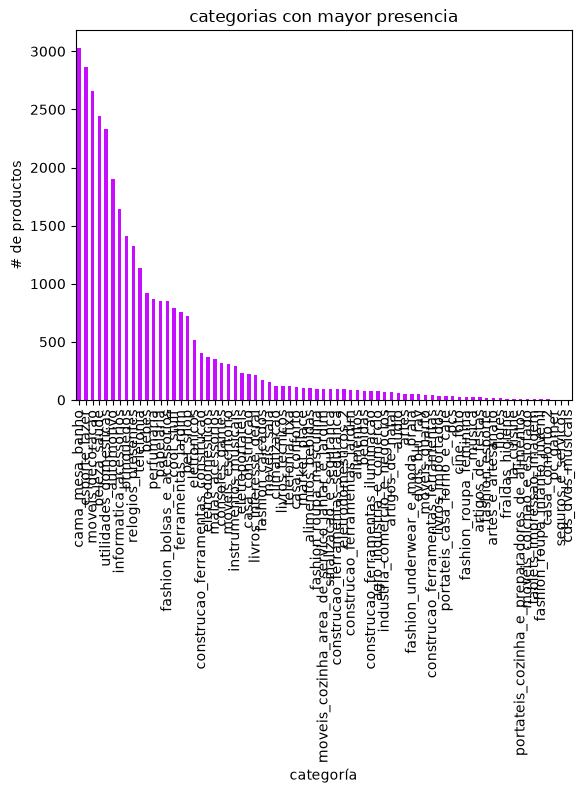

In [70]:
num_productos= products["product_category_name"].value_counts()
ax1 = num_productos.plot(kind="bar",
                title = "categorias con mayor presencia",
                xlabel = "categoría",
                ylabel = "# de productos",
                rot = 90,
                color = "#c70dff")
plt.show()

# 2 Las 10 categorías principales

Pregunta: ¿Cuáles son las categorías que tienen mayor presencia en el catálogo?

Requisitos:

Utiliza barras horizontales si consideras que facilitan la lectura./

Ordena los resultados.

Incluye título y etiquetas.

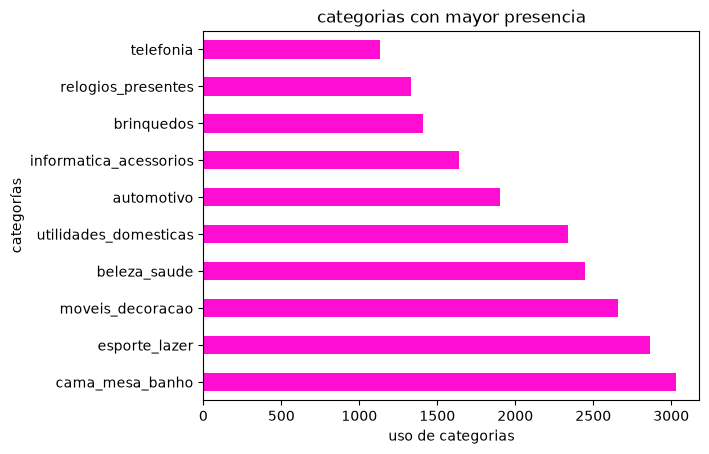

In [71]:
ax2 = num_productos.head(10).plot(kind="barh",
                title = "categorias con mayor presencia",
                rot = 0,
                xlabel = "uso de categorias",
                ylabel = "categorías",
                color = "#ff0dd3")
plt.show()

# 3 Distribución de productos

Pregunta: ¿Qué proporción del catálogo está concentrada en las principales categorías?

Requisitos:

Mostrar porcentajes.

Etiquetar las categorías.

Agregar un título.

Utilizar colores diferentes.

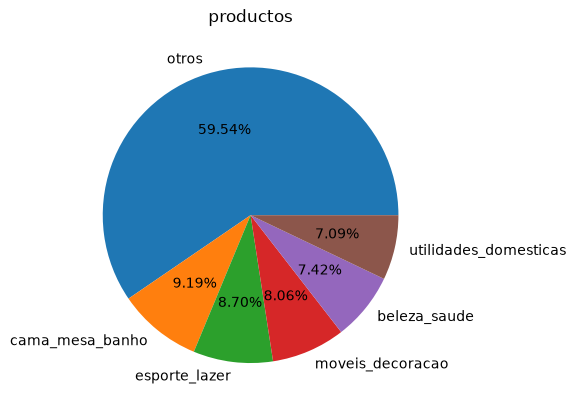

In [72]:
lol = products[["product_category_name", "product_id"]]
ax3= lol.groupby("product_category_name")["product_id"].count().nlargest(5)
lol["otros"] = lol['product_category_name'].apply(
    lambda x: x if x in ax3 else 'otros'
)
otros = lol["otros"].value_counts()
otros.plot(
    kind="pie",
    labels=otros.index,
    autopct='%1.2f%%',
    title="productos"
)
plt.show()

# 4 Clientes por estado


Pregunta: ¿Qué estados concentran la mayor cantidad de clientes?

Requisitos:

Mostrar todos los estados.

Ordenar de mayor a menor.

Utilizar barras horizontales.

Agregar título y etiquetas.

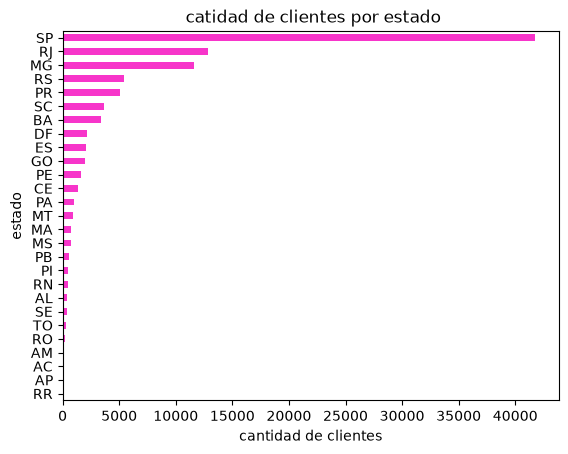

In [73]:
clientes = customers["customer_state"].value_counts().sort_values(ascending = True)
ax4 = clientes.plot(
    kind="barh",
    title=" catidad de clientes por estado",
    xlabel="cantidad de clientes",
    ylabel="estado",
    color = "#f735ca"
)
plt.show()

# 5 Estados principales

Pregunta: ¿Qué tan concentrada está la base de clientes geográficamente?

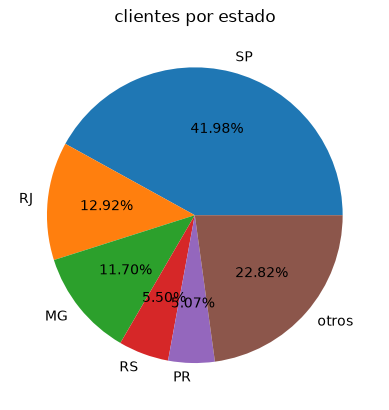

In [74]:
clientes2 = customers["customer_state"].value_counts()
lol = clientes2.head(5)
lol["otros"] = clientes2.iloc[5:].sum()
ax5 = lol.plot(
    kind="pie",
    autopct = "%1.2f%%",
    title = "clientes por estado",
    )


# 6 Métodos de pago

Pregunta: ¿Cuál es el método de pago más utilizado?

Después construye un pie chart utilizando exactamente la misma información.

Reflexión:

¿Cuál de las dos gráficas permite comparar mejor los métodos de pago?

¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?

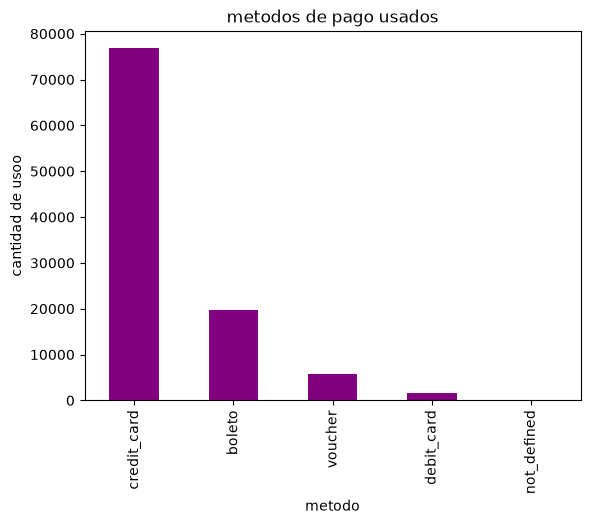

In [75]:
pagos = payments["payment_type"].value_counts()
ax6 = pagos.plot(
    kind="bar",
    title="metodos de pago usados",
    xlabel="metodo",
    ylabel="cantidad de usoo",
    color="purple"
)
plt.show()

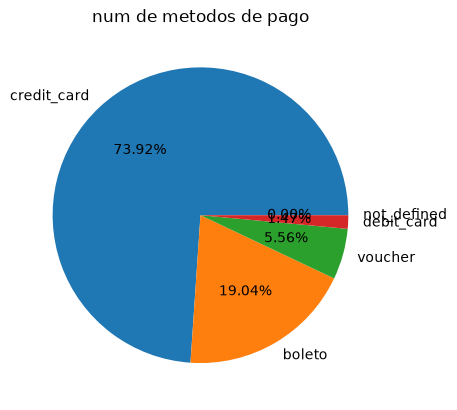

In [76]:
ax6_1 = pagos.plot(
                   kind = "pie",
                   title = "num de metodos de pago",
                   autopct = "%1.2f%%"
)
plt.show()

# 7 Número de cuotas

Pregunta: ¿Qué número de cuotas es el más frecuente?

Reto: Muestra únicamente los valores correspondientes a 1 a 10 cuotas.

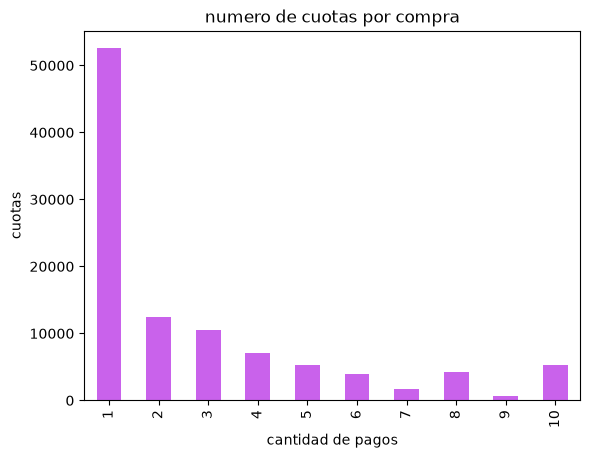

In [77]:
cant_pagos = payments["payment_installments"].value_counts().sort_index().iloc[1:11]
ax7 = cant_pagos.plot(
    kind="bar",
    title = "numero de cuotas por compra",
    xlabel="cantidad de pagos",
    ylabel= "cuotas",
    color = "#c962eb")
    
plt.show()


# 8 Comparando visualizaciones

Pregunta: ¿Cuál utilizarías en un reporte para comparar los métodos de pago?
R= yo utilizaria el de barras porque es mas facil para distinguirlo.
Pregunta: ¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?
R= en este caso utilizaria la de pastel porque esta representa un 100% y ya se ve como cuanto usa cada elemento.

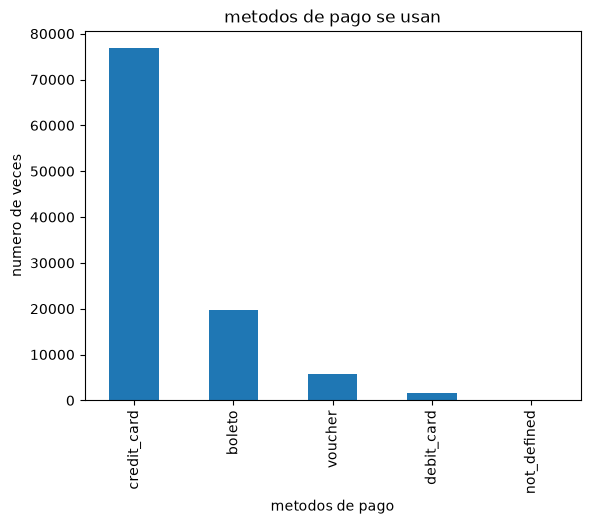

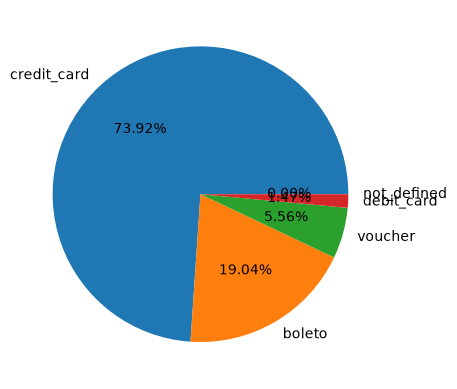

In [78]:
pagos = payments["payment_type"].value_counts()
ax8 = pagos.plot(kind= "bar"
                       )
ax8.set_title("metodos de pago se usan")
ax8.set_xlabel("metodos de pago")
ax8.set_ylabel("numero de veces")
plt.show()

ax8_2 = pagos.plot(
    kind="pie",
    autopct = "%1.2f%%"
)
ax2.set_title("metodos de pago")
plt.show()